In [1]:
import cv2
from ultralytics import YOLO
import matplotlib.pyplot as plt
import torch

In [2]:
print(torch.cuda.is_available())  # Dovrebbe restituire True
print(torch.cuda.device_count())  # Dovrebbe restituire il numero di GPU disponibili

print(torch.version.cuda)  # Mostra la versione di CUDA utilizzata da PyTorch
print(torch.backends.cudnn.version())  # Mostra la versione di cuDNN

False
0
11.8
90100


In [3]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Carica l'immagine originale
image_path = r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\1.jpg'
img = cv2.imread(image_path)

# Visualizza l'immagine con saturazione aumentata
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Immagine iniziale')
plt.axis('off')
plt.show()

# Funzione per aumentare il contrasto tramite equalizzazione dell'istogramma
def enhance_contrast(img):
    # Converti in YUV
    yuv_img = cv2.cvtColor(img, cv2.COLOR_BGR2YUV)
    # Equalizza solo il canale della luminanza (Y)
    yuv_img[:, :, 0] = cv2.equalizeHist(yuv_img[:, :, 0])
    # Riconverti in BGR
    return cv2.cvtColor(yuv_img, cv2.COLOR_YUV2BGR)

# Funzione per applicare la correzione gamma
def adjust_gamma(image, gamma=1.5):
    invGamma = 1.0 / gamma
    table = np.array([((i / 255.0) ** invGamma) * 255 for i in np.arange(0, 256)]).astype("uint8")
    return cv2.LUT(image, table)

# Aumenta il contrasto dell'immagine
img_enhanced = enhance_contrast(img)

# Visualizza l'immagine con saturazione aumentata
plt.imshow(cv2.cvtColor(img_enhanced, cv2.COLOR_BGR2RGB))
plt.title('Immagine con Contrasto Aumentato')
plt.axis('off')
plt.show()

# Salva l'immagine con saturazione aumentata
cv2.imwrite(r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\img_enhanced.jpg', img_enhanced)


# Applica la correzione gamma per esaltare le differenze tra le olive
img_gamma_corrected = adjust_gamma(img_enhanced, gamma=1.5)

# Visualizza l'immagine con saturazione aumentata
plt.imshow(cv2.cvtColor(img_gamma_corrected, cv2.COLOR_BGR2RGB))
plt.title('Immagine con Gamma Corretto')
plt.axis('off')
plt.show()

# Salva l'immagine con saturazione aumentata
cv2.imwrite(r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\img_gamma_corrected.jpg', img_gamma_corrected)

# Converti l'immagine in HSV
hsv_img = cv2.cvtColor(img_gamma_corrected, cv2.COLOR_BGR2HSV)

# Aumenta la saturazione (moltiplicando i valori del canale S per un fattore)
h, s, v = cv2.split(hsv_img)
s = cv2.multiply(s, 2)  # Aumenta la saturazione del 50% (puoi cambiare il fattore)
s = np.clip(s, 0, 255)  # Assicurati che i valori siano tra 0 e 255

# Riconverti l'immagine in BGR dopo aver modificato la saturazione
hsv_img_saturated = cv2.merge([h, s, v])
img_saturated = cv2.cvtColor(hsv_img_saturated, cv2.COLOR_HSV2BGR)

# Visualizza l'immagine con saturazione aumentata
plt.imshow(cv2.cvtColor(img_saturated, cv2.COLOR_BGR2RGB))
plt.title('Immagine con Saturazione Aumentata')
plt.axis('off')
plt.show()

# Salva l'immagine con saturazione aumentata
cv2.imwrite(r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\img_saturated.jpg', img_saturated)


FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\Bartolo\\OlivesDetectionProject\\neural_network\\data\\1.jpg'

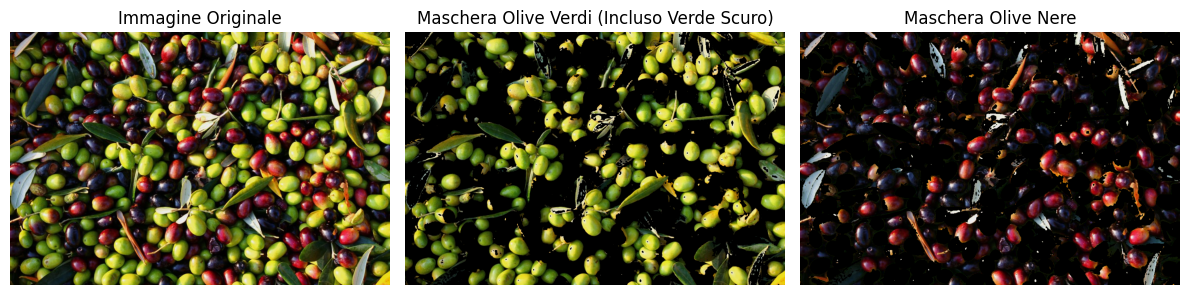

True

In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Funzione per calcolare la maschera delle olive verdi (incluso verde scuro e giallo molto chiaro)
def create_green_yellow_mask(image):
    hsv_img = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

    # Limiti estesi per includere verde scuro e giallo molto chiaro
    lower_green_yellow = np.array([20, 30, 30])  # Limite inferiore per verde scuro e giallo chiaro
    upper_green_yellow = np.array([85, 255, 255])  # Limite superiore esteso

    # Crea la maschera per il verde-giallo (compreso il verde scuro e il giallo chiaro)
    green_yellow_mask = cv2.inRange(hsv_img, lower_green_yellow, upper_green_yellow)

    # Applicare la maschera all'immagine originale
    masked_green_yellow = cv2.bitwise_and(image, image, mask=green_yellow_mask)

    return green_yellow_mask, masked_green_yellow

# Funzione per creare la maschera delle olive nere tramite sottrazione
def create_black_red_mask(image, green_yellow_mask):
    # Creare una maschera inversa per le olive nere (sottrazione del verde-giallo dall'immagine originale)
    black_red_mask = cv2.bitwise_not(green_yellow_mask)
    
    # Applicare la maschera all'immagine originale per estrarre le olive nere
    masked_black_red = cv2.bitwise_and(image, image, mask=black_red_mask)

    return black_red_mask, masked_black_red

# Carica l'immagine originale
image_path = r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\the-7-best-trees-to-plant-a-food-forest-1024x683.jpg'  # Cambia con il tuo percorso immagine
image = cv2.imread(image_path)

# Crea la maschera delle olive verdi e gialle (incluso verde scuro e giallo chiaro)
green_yellow_mask, masked_green_yellow = create_green_yellow_mask(image)

# Crea la maschera delle olive nere tramite sottrazione
black_red_mask, masked_black_red = create_black_red_mask(image, green_yellow_mask)

# Visualizza l'immagine originale e le maschere
plt.figure(figsize=(12, 6))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title('Immagine Originale')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(cv2.cvtColor(masked_green_yellow, cv2.COLOR_BGR2RGB))
plt.title('Maschera Olives Verdi (Incluso Verde Scuro)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(masked_black_red, cv2.COLOR_BGR2RGB))
plt.title('Maschera Olives Nere')
plt.axis('off')

plt.tight_layout()
plt.show()

# Salva le maschere generate
cv2.imwrite(r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\olive_verdi_gialle_con_verde_scuro.jpg', masked_green_yellow)
cv2.imwrite(r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\olive_nere_mask.jpg', masked_black_red)


In [3]:
# Funzione per la clusterizzazione K-means basata su colore
def cluster_olives_by_color(image, k=2):
    pixel_values = image.reshape((-1, 3))
    pixel_values = np.float32(pixel_values)

    # Definisci i criteri e applica K-means
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)
    _, labels, centers = cv2.kmeans(pixel_values, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)

    # Converti i centri in valori interi e riorganizza l'immagine
    centers = np.uint8(centers)
    segmented_image = centers[labels.flatten()]
    segmented_image = segmented_image.reshape(image.shape)

    return segmented_image, labels


# Applica K-means per segmentare olive verdi e nere
segmented_image, labels = cluster_olives_by_color(img_saturated, k=2)

# Visualizza i risultati della clusterizzazione
plt.imshow(cv2.cvtColor(segmented_image, cv2.COLOR_BGR2RGB))
plt.title('Clusterizzazione delle Olives')
plt.axis('off')
plt.show()

cv2.imwrite(r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\cluster_img_1.jpg', segmented_image)

# Applica K-means per segmentare olive verdi e nere
segmented_image, labels = cluster_olives_by_color(img_saturated, k=3)

# Visualizza i risultati della clusterizzazione
plt.imshow(cv2.cvtColor(segmented_image, cv2.COLOR_BGR2RGB))
plt.title('Clusterizzazione delle Olives')
plt.axis('off')
plt.show()

cv2.imwrite(r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\cluster_img_2.jpg', segmented_image)

# Applica K-means per segmentare olive verdi e nere
segmented_image, labels = cluster_olives_by_color(img_saturated, k=4)

# Visualizza i risultati della clusterizzazione
plt.imshow(cv2.cvtColor(segmented_image, cv2.COLOR_BGR2RGB))
plt.title('Clusterizzazione delle Olives')
plt.axis('off')
plt.show()

cv2.imwrite(r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\cluster_img_3.jpg', segmented_image)

# Applica K-means per segmentare olive verdi e nere
segmented_image, labels = cluster_olives_by_color(masked_green_yellow, k=2)

# Visualizza i risultati della clusterizzazione
plt.imshow(cv2.cvtColor(segmented_image, cv2.COLOR_BGR2RGB))
plt.title('Clusterizzazione delle Olives verdi')
plt.axis('off')
plt.show()

cv2.imwrite(r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\cluster_green_img_1.jpg', segmented_image)

# Applica K-means per segmentare olive verdi e nere
segmented_image, labels = cluster_olives_by_color(masked_green_yellow, k=3)

# Visualizza i risultati della clusterizzazione
plt.imshow(cv2.cvtColor(segmented_image, cv2.COLOR_BGR2RGB))
plt.title('Clusterizzazione delle Olives verdi')
plt.axis('off')
plt.show()

cv2.imwrite(r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\cluster_green_img_2.jpg', segmented_image)

segmented_image, labels = cluster_olives_by_color(masked_black_red, k=2)

# Visualizza i risultati della clusterizzazione
plt.imshow(cv2.cvtColor(segmented_image, cv2.COLOR_BGR2RGB))
plt.title('Clusterizzazione delle Olives nere')
plt.axis('off')
plt.show()

cv2.imwrite(r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\cluster_black_img_1.jpg', segmented_image)

segmented_image, labels = cluster_olives_by_color(masked_black_red, k=3)

# Visualizza i risultati della clusterizzazione
plt.imshow(cv2.cvtColor(segmented_image, cv2.COLOR_BGR2RGB))
plt.title('Clusterizzazione delle Olives nere')
plt.axis('off')
plt.show()

cv2.imwrite(r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\cluster_black_img_2.jpg', segmented_image)


NameError: name 'img_saturated' is not defined

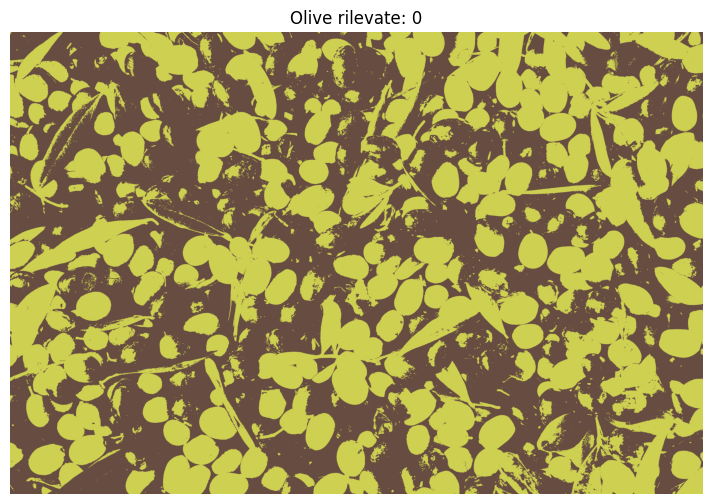

Numero totale di olive rilevate nell'immagine C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\cluster_img_1.jpg: 0


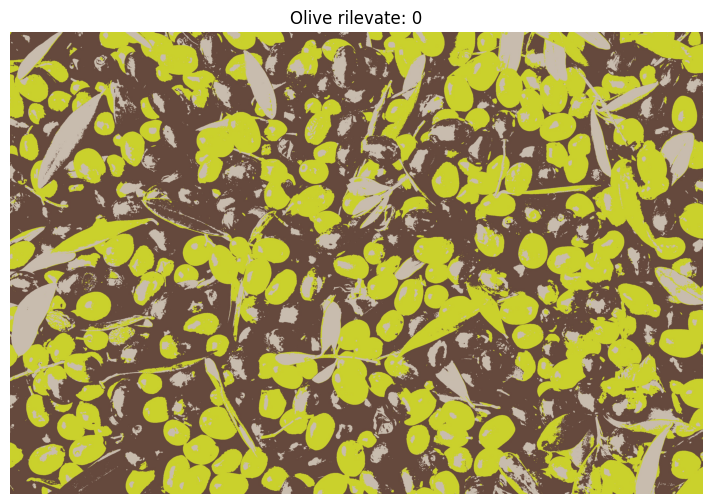

Numero totale di olive rilevate nell'immagine C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\cluster_img_2.jpg: 0


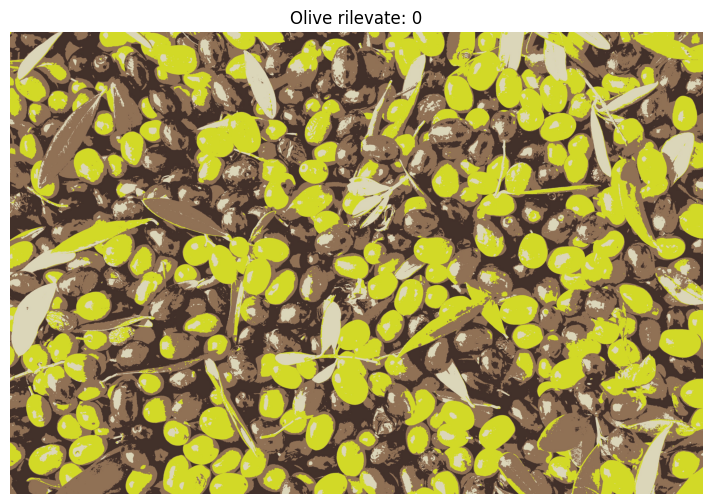

Numero totale di olive rilevate nell'immagine C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\cluster_img_3.jpg: 0


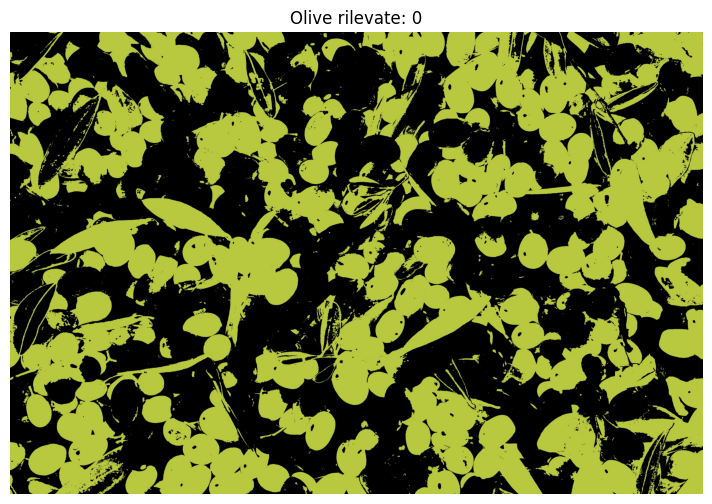

Numero totale di olive rilevate nell'immagine C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\cluster_green_img_1.jpg: 0


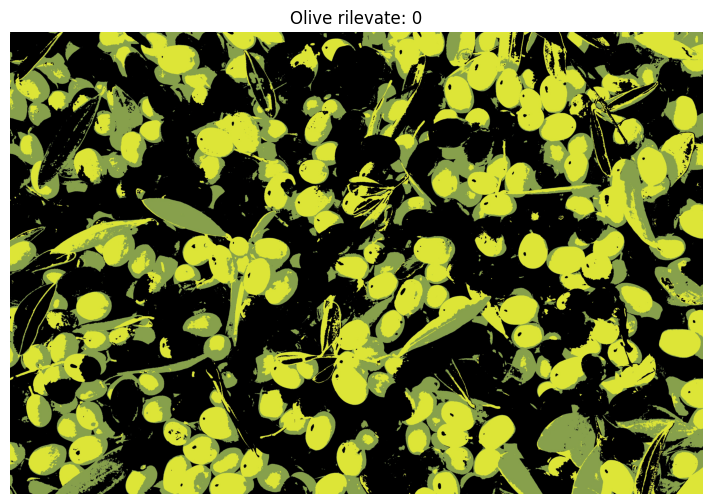

Numero totale di olive rilevate nell'immagine C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\cluster_green_img_2.jpg: 0


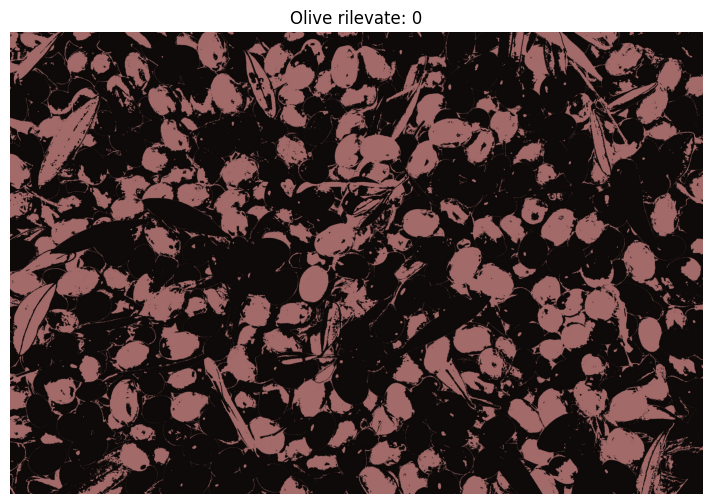

Numero totale di olive rilevate nell'immagine C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\cluster_black_img_1.jpg: 0


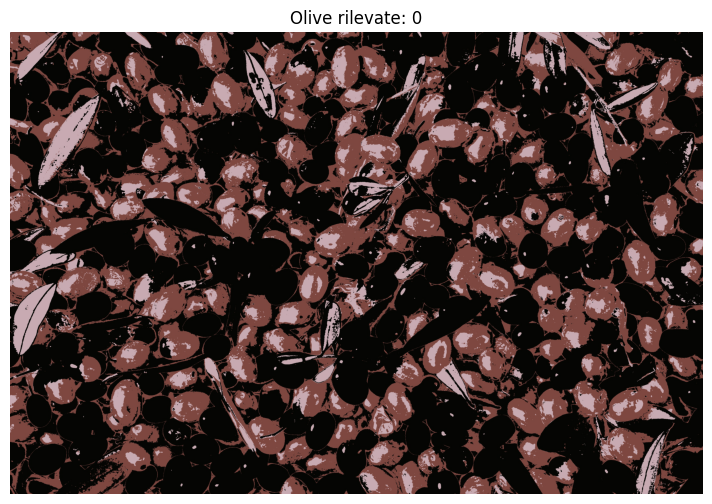

Numero totale di olive rilevate nell'immagine C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\cluster_black_img_2.jpg: 0


In [12]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Funzione per ridurre il rumore e migliorare i bordi
def preprocess_image(image):
    # Riduci il rumore con un filtro Gaussiano
    blurred = cv2.GaussianBlur(image, (5, 5), 0)
    
    # Aumenta il contrasto con CLAHE (Contrast Limited Adaptive Histogram Equalization)
    lab = cv2.cvtColor(blurred, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
    cl = clahe.apply(l)
    limg = cv2.merge((cl, a, b))
    enhanced_img = cv2.cvtColor(limg, cv2.COLOR_LAB2BGR)
    
    return enhanced_img

# Funzione per rilevare le olive tramite contorni
def detect_ellipses(binary_mask, min_area=300, max_area=3000, min_aspect_ratio=0.7, max_aspect_ratio=1.3):
    contours, _ = cv2.findContours(binary_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    ellipses = []
    for contour in contours:
        if len(contour) >= 5:
            ellipse = cv2.fitEllipse(contour)
            (x, y), (MA, ma), angle = ellipse
            area = np.pi * (MA / 2) * (ma / 2)
            aspect_ratio = MA / ma

            # Filtra per area e rapporto tra asse maggiore e minore
            if min_area < area < max_area and min_aspect_ratio < aspect_ratio < max_aspect_ratio:
                ellipses.append(ellipse)
    
    return ellipses

# Funzione per disegnare le ellissi rilevate
def draw_detected_olives(image, detected_ellipses):
    output_image = image.copy()
    for ellipse in detected_ellipses:
        cv2.ellipse(output_image, ellipse, (0, 255, 0), 2)  # Disegna ellissi in verde
    return output_image

# Funzione per filtrare e contare le olive
def process_image(image_path, min_area=300, max_area=3000, min_aspect_ratio=0.7, max_aspect_ratio=1.3):
    # Carica l'immagine originale
    img = cv2.imread(image_path)

    if img is None:
        raise FileNotFoundError(f"Impossibile trovare l'immagine: {image_path}")

    # Preprocessa l'immagine
    preprocessed_img = preprocess_image(img)

    # Converti in scala di grigi
    gray_img = cv2.cvtColor(preprocessed_img, cv2.COLOR_BGR2GRAY)

    # Applica una soglia per ottenere una maschera binaria (bianco e nero)
    _, binary_mask = cv2.threshold(gray_img, 1, 255, cv2.THRESH_BINARY)

    # Rileva ellissi sulle olive
    ellipses = detect_ellipses(binary_mask, min_area, max_area, min_aspect_ratio, max_aspect_ratio)

    # Disegna le ellissi rilevate
    image_with_ellipses = draw_detected_olives(img, ellipses)

    # Visualizza l'immagine originale con le olive rilevate
    plt.figure(figsize=(10, 6))
    plt.imshow(cv2.cvtColor(image_with_ellipses, cv2.COLOR_BGR2RGB))
    plt.title(f'Olives rilevate: {len(ellipses)}')
    plt.axis('off')
    plt.show()

    # Ritorna il numero di olive rilevate
    return len(ellipses)

# Percorsi delle immagini clusterizzate
image_paths = [
    r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\cluster_img_1.jpg',  
    r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\cluster_img_2.jpg',  
    r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\cluster_img_3.jpg',
    r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\cluster_green_img_1.jpg',  
    r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\cluster_green_img_2.jpg',  
    r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\cluster_black_img_1.jpg',  
    r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\cluster_black_img_2.jpg'
]

# Applica il processo di rilevamento delle olive a ciascuna immagine
for image_path in image_paths:
    olive_count = process_image(image_path)
    print(f'Numero totale di olive rilevate nell\'immagine {image_path}: {olive_count}')


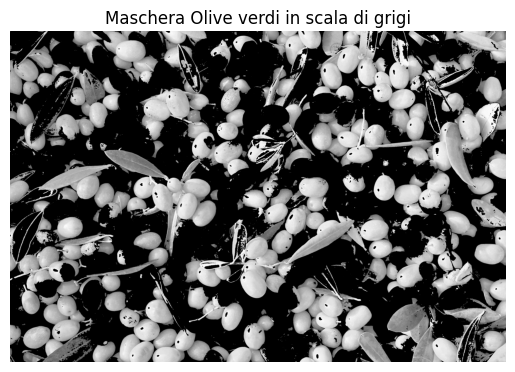

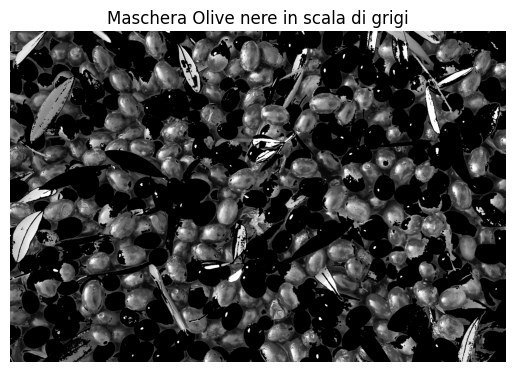

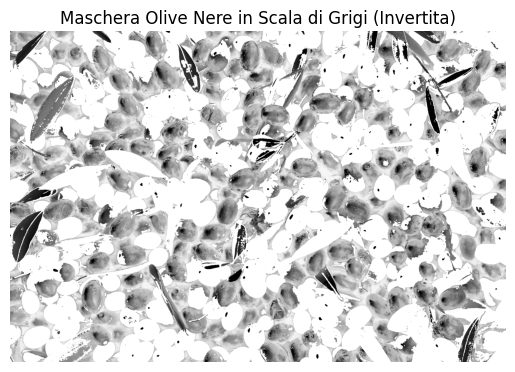

True

In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Carica la maschera verde-gialla
image_path = r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\olive_verdi_gialle_con_giallo_chiaro.jpg'  # Modifica il percorso se necessario
mask = cv2.imread(image_path)

# Converti la maschera in scala di grigi
gray_mask = cv2.cvtColor(mask, cv2.COLOR_BGR2GRAY)

# Visualizza la maschera binaria (bianco e nero)
plt.imshow(gray_mask, cmap='gray')
plt.title('Maschera Olives verdi in scala di grigi')
plt.axis('off')
plt.show()

# Salva l'immagine finale
cv2.imwrite(r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\maschera_verde_grigi.jpg', gray_mask)



# Carica la maschera verde-gialla
image_path = r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\olive_nere_mask.jpg'  # Modifica il percorso se necessario
mask = cv2.imread(image_path)

# Converti la maschera in scala di grigi
gray_mask = cv2.cvtColor(mask, cv2.COLOR_BGR2GRAY)

# Visualizza la maschera binaria (bianco e nero)
plt.imshow(gray_mask, cmap='gray')
plt.title('Maschera Olives nere in scala di grigi')
plt.axis('off')
plt.show()

# Salva l'immagine finale
cv2.imwrite(r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\maschera_nera_grigi.jpg', gray_mask)

import cv2
import matplotlib.pyplot as plt

# Carica la maschera verde-gialla (o nera)
image_path = r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\olive_nere_mask.jpg'  # Modifica il percorso se necessario
mask = cv2.imread(image_path)

# Converti la maschera in scala di grigi
gray_mask = cv2.cvtColor(mask, cv2.COLOR_BGR2GRAY)

# Inverti i valori della maschera (bianco diventa nero e viceversa)
inverted_mask = cv2.bitwise_not(gray_mask)

# Visualizza la maschera invertita
plt.imshow(inverted_mask, cmap='gray')
plt.title('Maschera Olives Nere in Scala di Grigi (Invertita)')
plt.axis('off')
plt.show()

# Salva l'immagine finale invertita
cv2.imwrite(r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\maschera_nera_grigi_invertita.jpg', inverted_mask)





0: 640x640 2 olives, 21.2ms
Speed: 10.2ms preprocess, 21.2ms inference, 141.7ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 olive, 20.0ms
Speed: 10.0ms preprocess, 20.0ms inference, 10.0ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 (no detections), 27.5ms
Speed: 0.0ms preprocess, 27.5ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 olive, 12.3ms
Speed: 9.0ms preprocess, 12.3ms inference, 10.0ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 3 olives, 24.4ms
Speed: 12.4ms preprocess, 24.4ms inference, 3.0ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 4 olives, 17.2ms
Speed: 7.1ms preprocess, 17.2ms inference, 0.0ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 2 olives, 30.2ms
Speed: 10.0ms preprocess, 30.2ms inference, 3.0ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 6 olives, 18.2ms
Speed: 6.4ms preprocess, 18.2ms inference, 0.0ms postprocess per image at sh

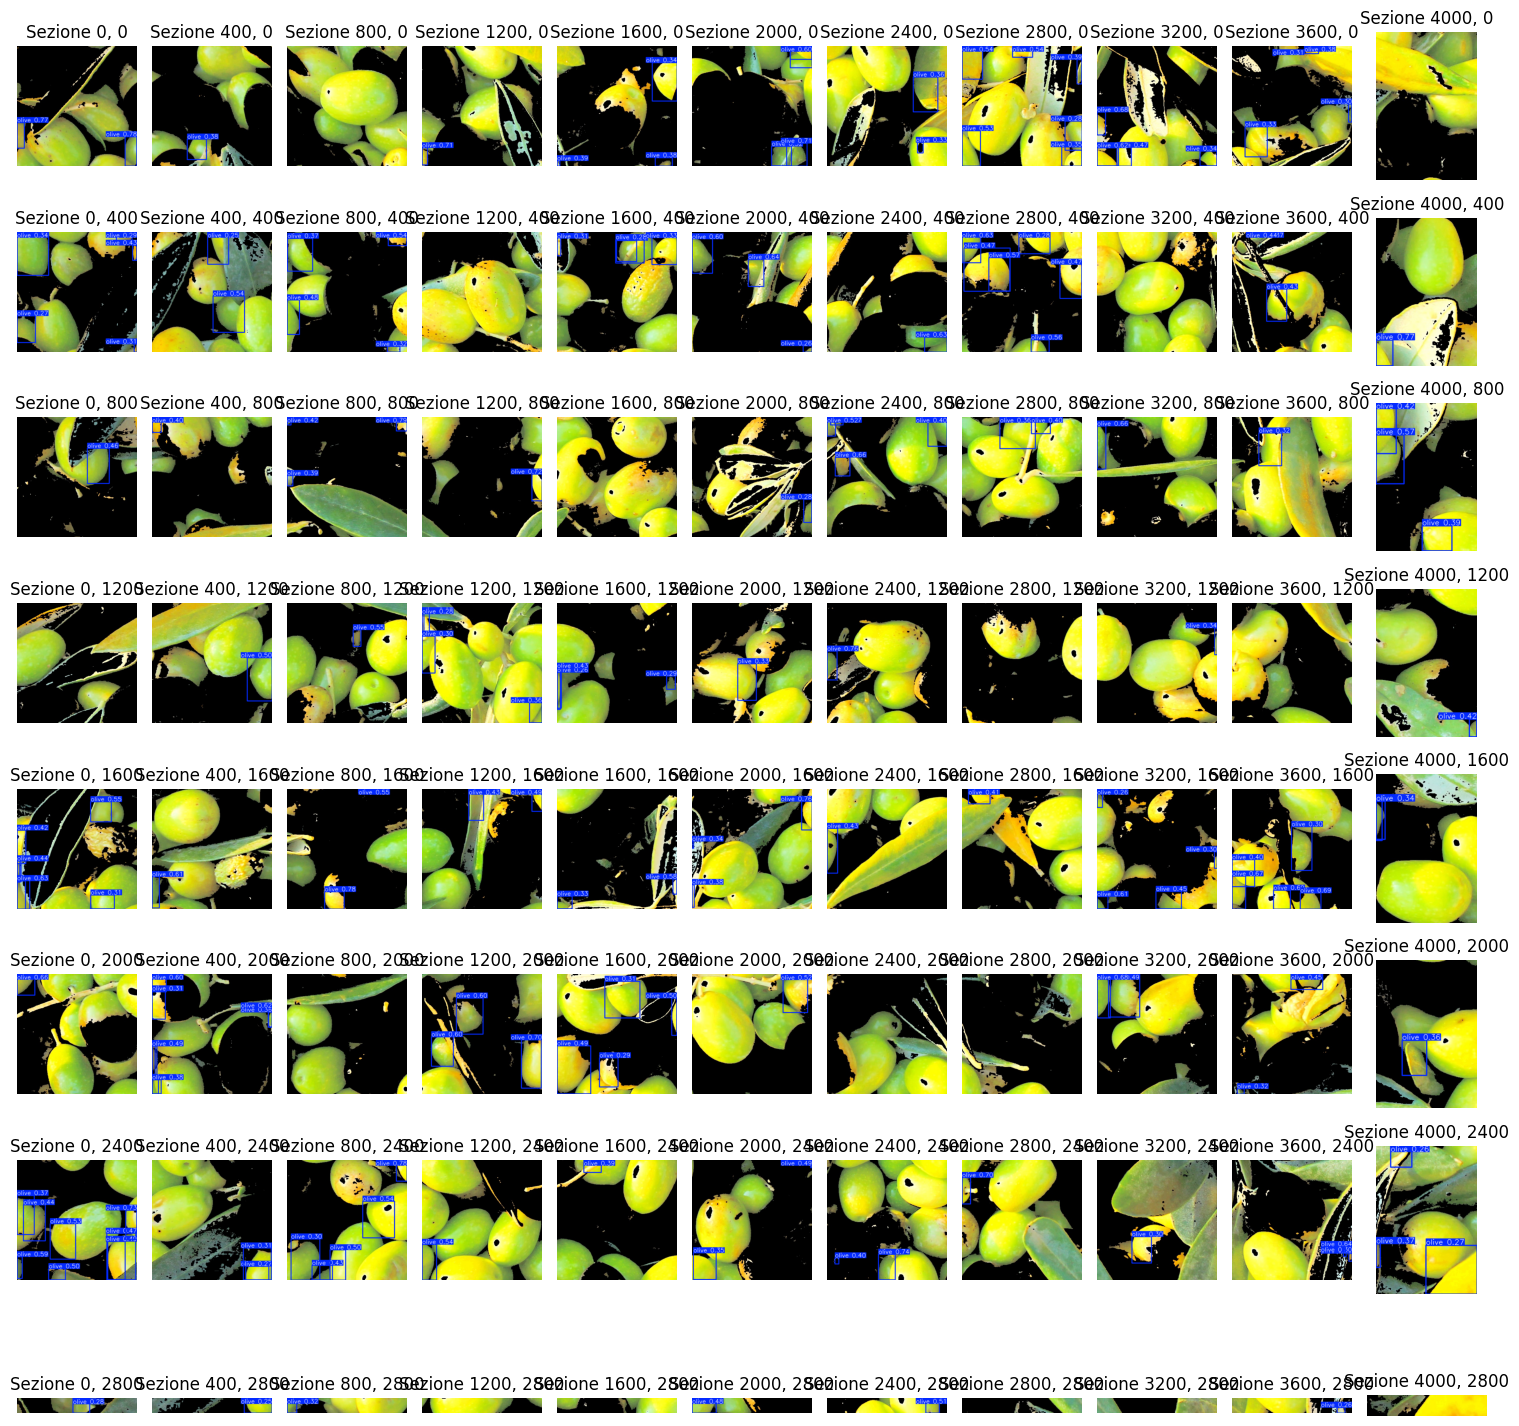

Totale olive rilevate: 174


In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Funzione per ridurre il rumore e migliorare i bordi
def preprocess_image(image):
    # Riduci il rumore con un filtro Gaussiano
    blurred = cv2.GaussianBlur(image, (5, 5), 0)
    
    # Aumenta il contrasto con CLAHE (Contrast Limited Adaptive Histogram Equalization)
    lab = cv2.cvtColor(blurred, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
    cl = clahe.apply(l)
    limg = cv2.merge((cl, a, b))
    enhanced_img = cv2.cvtColor(limg, cv2.COLOR_LAB2BGR)
    
    return enhanced_img

# Funzione per rilevare le olive tramite contorni
def detect_ellipses(binary_mask, min_area=300, max_area=3000, min_aspect_ratio=0.7, max_aspect_ratio=1.3):
    contours, _ = cv2.findContours(binary_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    ellipses = []
    for contour in contours:
        if len(contour) >= 5:
            ellipse = cv2.fitEllipse(contour)
            (x, y), (MA, ma), angle = ellipse
            area = np.pi * (MA / 2) * (ma / 2)
            aspect_ratio = MA / ma

            # Filtra per area e rapporto tra asse maggiore e minore
            if min_area < area < max_area and min_aspect_ratio < aspect_ratio < max_aspect_ratio:
                ellipses.append(ellipse)
    
    return ellipses

# Funzione per disegnare le ellissi rilevate
def draw_detected_olives(image, detected_ellipses):
    output_image = image.copy()
    for ellipse in detected_ellipses:
        cv2.ellipse(output_image, ellipse, (0, 255, 0), 2)  # Disegna ellissi in verde
    return output_image

# Funzione per filtrare e contare le olive
def process_image(image_path, min_area=300, max_area=3000, min_aspect_ratio=0.7, max_aspect_ratio=1.3):
    # Carica l'immagine originale
    img = cv2.imread(image_path)

    if img is None:
        raise FileNotFoundError(f"Impossibile trovare l'immagine: {image_path}")

    # Preprocessa l'immagine
    preprocessed_img = preprocess_image(img)

    # Converti in scala di grigi
    gray_img = cv2.cvtColor(preprocessed_img, cv2.COLOR_BGR2GRAY)

    # Applica una soglia per ottenere una maschera binaria (bianco e nero)
    _, binary_mask = cv2.threshold(gray_img, 1, 255, cv2.THRESH_BINARY)

    # Rileva ellissi sulle olive
    ellipses = detect_ellipses(binary_mask, min_area, max_area, min_aspect_ratio, max_aspect_ratio)

    # Disegna le ellissi rilevate
    image_with_ellipses = draw_detected_olives(img, ellipses)

    # Visualizza l'immagine originale con le olive rilevate
    plt.figure(figsize=(10, 6))
    plt.imshow(cv2.cvtColor(image_with_ellipses, cv2.COLOR_BGR2RGB))
    plt.title(f'Olives rilevate: {len(ellipses)}')
    plt.axis('off')
    plt.show()

    # Ritorna il numero di olive rilevate
    return len(ellipses)

# Percorsi delle immagini clusterizzate
image_paths = [
    r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\cluster_img_1.jpg',  
    r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\cluster_img_2.jpg',  
    r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\cluster_img_3.jpg',
    r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\cluster_green_img_1.jpg',  
    r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\cluster_green_img_2.jpg',  
    r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\cluster_black_img_1.jpg',  
    r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\cluster_black_img_2.jpg'
]

# Applica il processo di rilevamento delle olive a ciascuna immagine
for image_path in image_paths:
    olive_count = process_image(image_path)
    print(f'Numero totale di olive rilevate nell\'immagine {image_path}: {olive_count}')


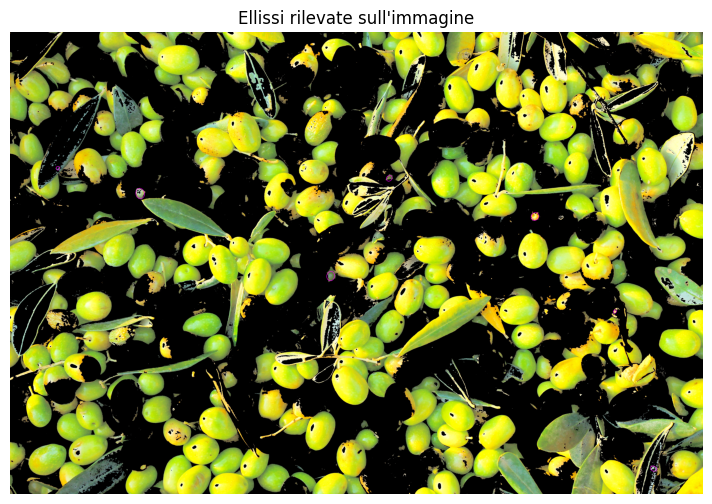

True

In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Funzione per rilevare ellissi
def detect_ellipses(binary_mask, min_area=300, max_area=3000, min_aspect_ratio=0.7, max_aspect_ratio=1.3):
    # Trova i contorni nell'immagine binaria
    contours, _ = cv2.findContours(binary_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    ellipses = []
    for contour in contours:
        if len(contour) >= 5:  # Necessario per calcolare l'ellisse
            ellipse = cv2.fitEllipse(contour)
            (x, y), (MA, ma), angle = ellipse
            area = np.pi * (MA / 2) * (ma / 2)  # Calcola l'area dell'ellisse
            aspect_ratio = MA / ma  # Calcola il rapporto tra asse maggiore e minore
            if min_area < area < max_area and min_aspect_ratio < aspect_ratio < max_aspect_ratio:
                ellipses.append(ellipse)
    return ellipses

# Funzione per visualizzare le ellissi
def draw_detected_olives(image, detected_olives):
    output_image = image.copy()
    for ellipse in detected_olives:
        cv2.ellipse(output_image, ellipse, (255, 0, 255), 2)  # Disegna ellissi in verde
    return output_image

# Carica l'immagine
image_path = r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\olive_verdi_gialle_con_giallo_chiaro.jpg'  # Cambia con il percorso corretto
img = cv2.imread(image_path)

# Converti l'immagine a colori in scala di grigi
gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Applica una soglia per ottenere un'immagine binaria
_, binary_img = cv2.threshold(gray_img, 100, 255, cv2.THRESH_BINARY)

# Rileva ellissi sulle olive
ellipses = detect_ellipses(binary_img)

# Disegna le ellissi rilevate sull'immagine originale
image_with_ellipses = draw_detected_olives(img, ellipses)

# Visualizza l'immagine con le ellissi
plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(image_with_ellipses, cv2.COLOR_BGR2RGB))
plt.title('Ellissi rilevate sull\'immagine')
plt.axis('off')
plt.show()

# Salva l'immagine finale
cv2.imwrite(r'C:\Users\Bartolo\OlivesDetectionProject\neural_network\data\saved\olive_verdi_gialle_rilevate.jpg', image_with_ellipses)
